# CHLA-Z methods 6: glider retrieval, QC and solar-time windows

**Author:** Eli Holmes (NOAA)<br>
Last updated: November 25, 2026

> **What this notebook is.** One of the *data methods* notebooks for the
> CHLA-Z tables in `datasets/chla_z/data/`, for the glider tables
> (`CHLA_glider_profiles*.parquet`): chlorophyll profiles from 280 IOOS Glider
> DAC deployments, mostly coastal, where OOI has only a few sites. It shows,
> on one Slocum and one Spray deployment, how glider chlorophyll is
> selected, retrieved, quality controlled, reduced to one profile per 3 h
> window, binned and corrected, and checks the result against the released
> table. It is **not** about model training.
>
> **What it is not.** It does not build the tables. The build runs from
> `datasets/chla_z/build.py` (stages `glider-fetch`, `glider`, then `pace`,
> `olci` and their merges with `--platform glider`), which calls the
> functions in `src/chla_z_glider.py` that this notebook calls. The raw
> downloads it reads are on the hub in `notebooks/_temp_data/glider/`.
> Design note and decisions: `claude/notes/chla-z-glider.md`.

The processing follows OOI (methods notebook 2) wherever it can: 3 h windows
of local mean solar time, 10 m bins (A, B] from 0 to 200 m, and the Sauzède
fluorescence:chla correction. The deliberate difference is that a glider
moves, so a window keeps **one** profile instead of averaging all samples.
The table also keeps the fluorometer values and a deep (dark) offset as
columns (section 5), and two per-row QC columns from the deployment scan
(section 6). Matchups to PACE and OLCI use the same code and rules as
Argo and OOI (methods notebooks 3 and 4).

In [1]:
import sys

if "../../../src" not in sys.path:
    sys.path.insert(0, "../../../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import chla_z_build as b
import chla_z_glider as g

## 1. Which deployments

The first release (2026_11_24) had 20 deployments chosen by hand after a
one-day sensor screen. Since #19 the table takes its deployments from a scan
of the **whole** Glider DAC (`build.py glider-scan`, `src/chla_z_glider_scan.py`,
issue #16): every tabledap dataset with a chlorophyll variable
(`chlorophyll_a`, `chlorophyll`, `fluorescence`, or a raw Slocum
`sci_*_chlor*` name) and at least 7 days of record since 2024-03-01, one
dataset per deployment. Each deployment's whole record is checked on every
4th day (daily 10 m-bin means computed by ERDDAP). The result is committed as
`src/chla_z_glider_candidates.csv`; `g.meta()` reads it, and the fetch and
the table take each deployment's chlorophyll variable, QC variable and
region from there.

In [2]:
meta = g.meta()
print(len(meta), "deployments scanned")
meta.groupby("verdict").size().rename("deployments").to_frame()

316 deployments scanned


,deployments
verdict,
check,46
fail,51
ok,217
too few days,2


`fail` means the sensor or its processing is wrong for this use; `check`
means it could be real ocean (upwelling, a mixed shelf) and was looked at on
a plot. The reasons:

In [3]:
pd.concat([meta.fail.str.split("; ").explode().value_counts().rename("fail"),
           meta.check.str.split("; ").explode().str.replace(r"^\d+ ", "N ", regex=True)
           .value_counts().rename("check")], axis=1).fillna(0).astype(int)

,fail,check
deep offset > 0.2,24,0
negative offset,13,0
flat,10,2
no signal above deep value,7,0
implausibly high,2,0
surface < deep for 16 d,2,0
surface < deep for 14 d,1,0
surface < deep for 25 d,1,0
surface < deep for 36 d,1,0
N whole-column bad day(s),0,34


**Selection (Eli Holmes, 2026-11-24).** `ok` and `check` deployments, plus
those whose *only* failure is the deep offset (> 0.2 below 300 m), with some
record inside the release months (`g.select_from_scan`, written to
`src/chla_z_glider_selection.json` by `g.write_selection`). The deep-offset
deployments are kept but flagged on every row (`deep_offset_flag`) so an
analysis can drop them in its QC step; the `check` notes are kept on every
row too (`scan_check`). Negative offset, flat, signal-free, surface-below-deep
and implausibly high deployments are left out.

Region names are labels of the deployment centre (`chla_z_glider_scan.region`),
not a claim of coverage. No deployment is in the Gulf of Mexico: the USF and
Skidaway gliders are on the Atlantic shelf off Georgia and NE Florida.

In [4]:
sel = meta.loc[g.selection()]
assert sel.index.equals(pd.Index(g.select_from_scan(meta).reset_index()
                                 .sort_values(["region", "minTime"]).datasetID))
print(len(sel), "deployments in the table")
sel.assign(deep_offset=sel.fail.notna()).groupby("region").agg(
    deployments=("verdict", "size"), check=("verdict", lambda s: (s == "check").sum()),
    deep_offset=("deep_offset", "sum"), days=("days_in_months", "sum"),
    platforms=("platform_type", lambda s: ", ".join(sorted(s.dropna().unique())))).round(0)

280 deployments in the table


,deployments,check,deep_offset,days,platforms
region,,,,,
Antarctic Peninsula,2,0,0,129.0,Slocum Glider
British Columbia / Salish Sea,19,9,0,959.0,Slocum Glider
California Current,58,14,19,4885.0,"Seaglider, Slocum Glider, Spray Glider"
Great Lakes,1,0,0,13.0,Slocum Glider
Gulf of Alaska / Bering,15,1,0,1510.0,Slocum Glider
Irminger / subpolar N Atlantic,5,2,0,1118.0,Slocum Glider
Mid-Atlantic Bight and slope,93,3,0,3535.0,"Slocum Glider, Spray Glider"
Open NW Atlantic (slope sea / Gulf Stream),4,0,0,248.0,"Slocum Glider, Spray Glider"
Pacific Northwest (OR/WA),42,12,0,3195.0,"Seaglider, Slocum Glider"


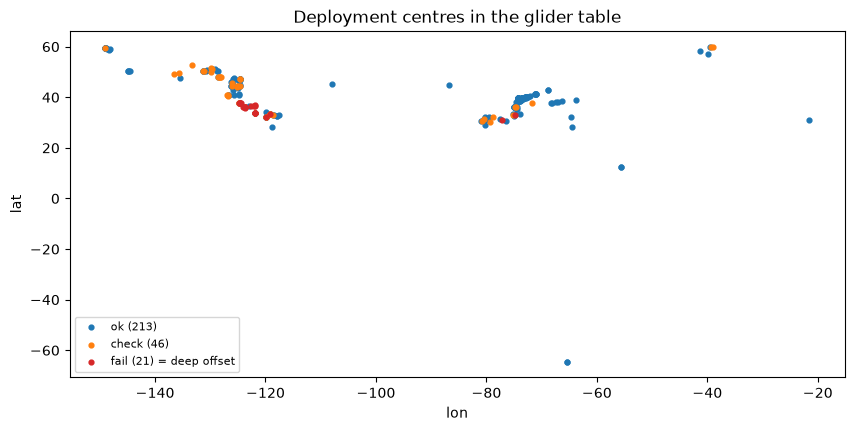

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for v_, c_ in (("ok", "C0"), ("check", "C1"), ("fail", "C3")):
    x = sel[sel.verdict == v_]
    ax.scatter(x.lon, x.lat, s=12, color=c_, label=f"{v_} ({len(x)})" + (" = deep offset" if v_ == "fail" else ""))
ax.set_xlabel("lon"); ax.set_ylabel("lat"); ax.legend(fontsize=8)
ax.set_title("Deployment centres in the glider table");

## 2. Retrieve one deployment-month

A Rutgers Slocum on the Mid-Atlantic shelf, May 2024. `g.fetch_unit` asks
for the samples with chlorophyll in 0–200 m (`chlorophyll_a!=NaN`, so the
many CTD-only rows of a Slocum are not downloaded), with each sample's own
time (`precise_time`) and, for Slocums, position (`precise_lat/lon`). The
build saves one gzipped CSV per deployment-month; here we read that file.

In [6]:
slocum = "ru39-20240429T1522-delayed"
raw = pd.read_csv(g.RAW_DIR / slocum / "2024-05.csv.gz")
print(len(raw), "samples,", raw.profile_id.nunique(), "profiles")
raw.head()

301930 samples, 3638 profiles


,profile_id,time,latitude,longitude,precise_time,depth,chlorophyll_a,chlorophyll_a_qartod_summary_flag,precise_lat,precise_lon
0,1714521621,2024-05-01T00:00:21Z,40.128615,-73.654811,2024-04-30T23:57:26Z,2.411343,1.0950,1,40.129070,-73.655109
1,1714521621,2024-05-01T00:00:21Z,40.128615,-73.654811,2024-04-30T23:57:30Z,2.589960,1.1388,1,40.129059,-73.655102
2,1714521621,2024-05-01T00:00:21Z,40.128615,-73.654811,2024-04-30T23:57:32Z,2.828115,1.1096,1,40.129054,-73.655099
3,1714521621,2024-05-01T00:00:21Z,40.128615,-73.654811,2024-04-30T23:57:34Z,3.125809,1.1169,1,40.129049,-73.655095
4,1714521621,2024-05-01T00:00:21Z,40.128615,-73.654811,2024-04-30T23:57:36Z,3.492964,1.1388,1,40.129044,-73.655092


## 3. Quality control

`g.good_samples` keeps depth in (0, 200] m and, where the dataset has a
chlorophyll flag, flag 0, 1 or 2 (no QC performed / good / not evaluated), and
values in (-5, 100) (outside is a fill value). A sample's time is its
`precise_time`: on some delayed-mode Slocum sets the profile `time` is about
70 minutes away from the chlorophyll samples it labels.

In [7]:
qc_var = sel.loc[slocum, "qc_var"]
print("flag counts:", raw[qc_var].value_counts().sort_index().to_dict())
good = g.good_samples(raw, qc_var)
print(f"{len(good)} of {len(raw)} samples kept")

flag counts: {1: 301930}


301906 of 301930 samples kept


Datasets name their chlorophyll differently. The raw CSV keeps the dataset's
own names; `g._standard` renames the chlorophyll column to `chlorophyll_a`
when it is read. The Oregon State Seagliders, for example, publish
`fluorescence` with a `fluorescence_qc` flag that is 0 ("no QC performed") on
every value, so flag 0 is kept: it is the same situation as the many
datasets that have no flag at all.

In [8]:
osu = "OSU686-20240412T0000"
print(meta.loc[osu, ["chl_var", "chl_units", "qc_var", "platform_type"]].to_dict())
oraw = g._standard(pd.read_csv(sorted((g.RAW_DIR / osu).glob("*.csv.gz"))[0]), osu)
print("flag counts:", oraw[meta.loc[osu, "qc_var"]].value_counts().to_dict())
print(len(g.good_samples(oraw, meta.loc[osu, "qc_var"])), "of", len(oraw), "samples kept")

{'chl_var': 'fluorescence', 'chl_units': 'microgram/L', 'qc_var': 'fluorescence_qc', 'platform_type': 'Seaglider'}
flag counts: {0: 49411}
49367 of 49411 samples kept


A Slocum profiles continuously in a sawtooth: each dive and each climb is a
profile. Within one 10 m bin it moves only tens of metres horizontally
(measured on six deployments, 2026-11-23), so one position per profile is
accurate at the scale of a 4 km satellite pixel.

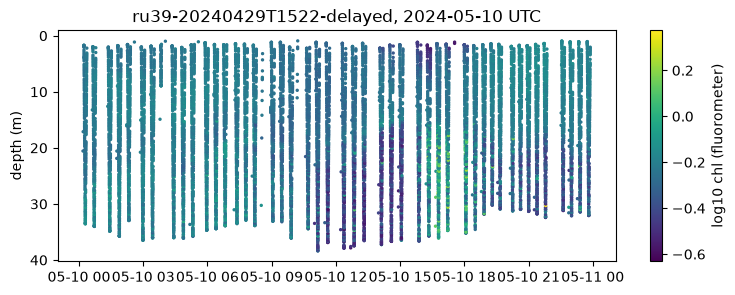

In [9]:
day = good[(good.t >= "2024-05-10") & (good.t < "2024-05-11")]
fig, ax = plt.subplots(figsize=(9, 3))
s = ax.scatter(day.t, day.depth, c=np.log10(day.chlorophyll_a.clip(lower=0.01)), s=2)
ax.invert_yaxis(); ax.set_ylabel("depth (m)")
fig.colorbar(s, label="log10 chl (fluorometer)"); ax.set_title(f"{slocum}, 2024-05-10 UTC");

## 4. One profile per 3 h window of local solar time

Like OOI, rows are 3 h windows of local mean solar time (UTC + lon/15 h),
so each row keeps its time of day (quenching). Unlike OOI, a window keeps
one glider profile rather than averaging all samples: a glider travels
10–80 km a day, and an average would mix positions. `g.window_profiles`
picks the profile with the most filled 10 m bins, ties going to the profile
nearest the window centre. Its time is its mean sample time; lat/lon its mean
sample position. `profile_id` is `<dataset>_<solar date>T<window start hour>`
as for OOI; `glider_profile_id` is the Glider DAC profile.

A glider profile is identified by its DAC `profile_id` **and** its profile
`time`: in 27 of the selected datasets (DFO / C-PROOF mostly) the same
`profile_id` labels profiles days apart, and grouping by the id alone merged
them (positions jumping ~45 km between windows; found while re-running this
notebook, 2026-11-25).

In [10]:
win = g.window_profiles(good, slocum)
print(len(win), "windows from", good.profile_id.nunique(), "profiles")
win[["profile_id", "time", "lat", "lon", "glider_profile_id", "profiles_in_window",
     "max_depth", "CHLA_0_10", "CHLA_20_30"]].head(8)

231 windows from 3638 profiles


,profile_id,time,lat,lon,glider_profile_id,profiles_in_window,max_depth,CHLA_0_10,CHLA_20_30
0,ru39-20240429T1522-delayed_20240430T18,2024-05-01 00:35:13.594936832+00:00,40.123168,-73.651251,1714523714,9,46.108303,1.213503,1.057689
1,ru39-20240429T1522-delayed_20240430T21,2024-05-01 03:17:00.787878912+00:00,40.103330,-73.634225,1714533426,16,40.760860,1.020053,1.168456
2,ru39-20240429T1522-delayed_20240501T00,2024-05-01 07:09:11.700000+00:00,40.079715,-73.604936,1714547352,14,40.522840,0.892164,1.110434
3,ru39-20240429T1522-delayed_20240501T03,2024-05-01 09:22:10.249999872+00:00,40.060347,-73.585521,1714555331,18,37.764748,0.809570,1.072694
4,ru39-20240429T1522-delayed_20240501T06,2024-05-01 12:11:16.893129728+00:00,40.037576,-73.563985,1714565477,15,41.286938,0.348453,1.577843
5,ru39-20240429T1522-delayed_20240501T09,2024-05-01 14:55:07.885245952+00:00,40.022782,-73.549944,1714575317,15,40.572655,0.197448,1.499922
6,ru39-20240429T1522-delayed_20240501T12,2024-05-01 18:18:25.546874880+00:00,40.007564,-73.529378,1714587511,16,41.455715,0.195275,1.391424
7,ru39-20240429T1522-delayed_20240501T15,2024-05-01 21:23:27.414966016+00:00,39.985232,-73.503548,1714598607,16,40.086643,0.381790,1.118245


The shelf is about 40–80 m deep here, so the deeper bins are empty (NaN). On
the shelf that is real, and a model has to accept it.

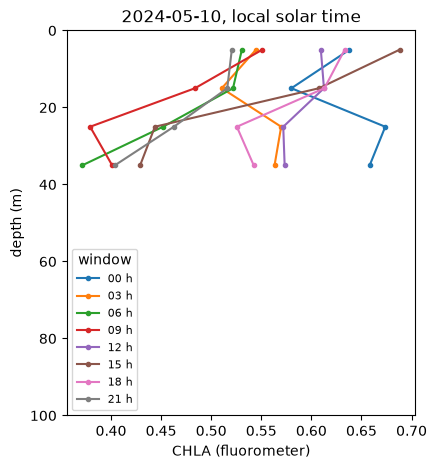

In [11]:
mid = np.arange(5, 200, 10)
d = win[win.profile_id.str.contains("_20240510T")]
fig, ax = plt.subplots(figsize=(4.5, 5))
for _, r in d.iterrows():
    ax.plot(r[b.CHLA_COLS].to_numpy(float), mid, marker=".", label=r.profile_id[-2:] + " h")
ax.set_ylim(100, 0); ax.set_xlabel("CHLA (fluorometer)"); ax.set_ylabel("depth (m)")
ax.legend(title="window", fontsize=8); ax.set_title("2024-05-10, local solar time");

A Spray records only on the way up, one profile every 2–3 hours, so most
windows hold one profile already. Sprays carry no per-sample position
(`precise_lat` is empty), so they use the profile position. Example: off
Cape Hatteras, November 2024.

In [12]:
spray = "sp066-20241106T1639"
sraw = pd.read_csv(g.RAW_DIR / spray / "2024-11.csv.gz")
swin = g.window_profiles(g.good_samples(sraw, sel.loc[spray, "qc_var"]), spray)
print(len(swin), "windows;", swin.profiles_in_window.value_counts().sort_index().to_dict(),
      "(profiles per window: count)")

158 windows; {1: 117, 2: 30, 3: 7, 4: 2, 5: 1, 6: 1} (profiles per window: count)


## 5. Sauzède correction, raw values and the dark offset

**Sauzède.** Glider fluorometers (WET Labs ECO on Slocums, an equivalent on
Sprays) are factory-calibrated, like OOI's. The table divides by the Sauzède
ratio at the profile position, as for OOI: `CHLA_A_B = CHLA_FLUOR_A_B /
chla_ratio`. The ratio differs a lot by region:

In [13]:
prof = pd.read_parquet(b.DATA_DIR / "CHLA_glider_profiles.parquet")
prof.groupby("region").chla_ratio.agg(["min", "median", "max"]).round(2)

,min,median,max
region,,,
Antarctic Peninsula,2.91,2.91,3.35
British Columbia / Salish Sea,0.42,0.55,1.28
California Current,0.89,1.66,2.27
Great Lakes,1.32,1.32,1.32
Gulf of Alaska / Bering,0.36,1.01,1.51
Irminger / subpolar N Atlantic,2.45,2.45,2.66
Mid-Atlantic Bight and slope,1.19,1.33,1.61
Open NW Atlantic (slope sea / Gulf Stream),1.20,1.46,1.89
Pacific Northwest (OR/WA),0.48,0.80,1.83


**Raw values are kept.** `CHLA_FLUOR_A_B` are the fluorometer bin means as
published (after QC, nothing subtracted or divided). The raw ERDDAP samples
are also kept on the hub (`_temp_data/glider/raw/`, `raw_deep/`).

In [14]:
fluor = [c.replace("CHLA_", "CHLA_FLUOR_") for c in b.CHLA_COLS]
back = prof[b.CHLA_COLS].to_numpy() * prof.chla_ratio.fillna(1).to_numpy()[:, None]
print("max |CHLA * chla_ratio - CHLA_FLUOR|:", np.nanmax(np.abs(back - prof[fluor].to_numpy())))

max |CHLA * chla_ratio - CHLA_FLUOR|: 3.552713678800501e-15


**Dark offset (a column, not subtracted).** Below 300 m a fluorometer should
read about 0. Glider fluorometers often do not, and the offset drifts within
a deployment. For every glider profile that reaches 300 m, `g.dark_series`
takes the centred 3-day running median of all QC-passing samples below 300 m
(fetched separately by `g.fetch_deep_unit`); 300 m, not 150 m, because East
Coast Sprays still have real chlorophyll at 150–200 m. Gliders that never
reach 300 m (the shelf Slocums, capex690) get NaN: their deepest water can
hold real chlorophyll, so it is not a dark reference.

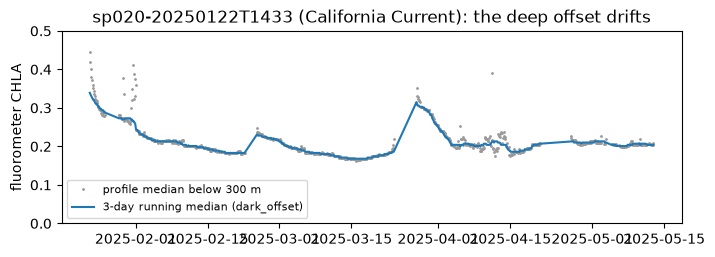

In [15]:
ds = g.dark_series("sp020-20250122T1433")
fig, ax = plt.subplots(figsize=(8, 2.5))
ax.plot(ds.t, ds.dark_profile, ".", ms=2, color="0.6", label="profile median below 300 m")
ax.plot(ds.t, ds.dark_smooth, lw=1.5, label="3-day running median (dark_offset)")
ax.set_ylabel("fluorometer CHLA"); ax.set_ylim(0, 0.5); ax.legend(fontsize=8)
ax.set_title("sp020-20250122T1433 (California Current): the deep offset drifts");

In [16]:
prof.groupby("region").agg(
    rows=("profile_id", "size"), dark_offset_rows=("dark_offset", "count"),
    dark_offset=("dark_offset", "median"),
    fluor_150_160=("CHLA_FLUOR_150_160", "median"), fluor_190_200=("CHLA_FLUOR_190_200", "median")).round(3)

,rows,dark_offset_rows,dark_offset,fluor_150_160,fluor_190_200
region,,,,,
Antarctic Peninsula,955,951,0.102,0.115,0.105
British Columbia / Salish Sea,4245,1840,0.036,0.036,0.036
California Current,32217,31998,0.186,0.183,0.180
Great Lakes,104,0,NaN,NaN,NaN
Gulf of Alaska / Bering,8189,1716,0.054,0.064,0.065
Irminger / subpolar N Atlantic,3465,1731,0.022,0.034,0.029
Mid-Atlantic Bight and slope,22564,7188,0.007,0.034,0.026
Open NW Atlantic (slope sea / Gulf Stream),1975,1843,0.039,0.054,0.042
Pacific Northwest (OR/WA),15976,12219,0.048,0.041,0.042


Why it is not subtracted: it makes the gliders disagree with PACE and with
Argo (section 9, last cell). A user who wants it removed computes
`(CHLA_FLUOR_A_B - dark_offset) / chla_ratio`.

## 6. QC columns and whole-column failures

Two per-deployment scan results are on every row, so QC is a one-line filter:

- `deep_offset_flag`: the deployment's median fluorometer value below 300 m
  is > 0.2 on its whole record (mostly California Current Sprays).
  `prof[~prof.deep_offset_flag]` drops them.
- `scan_check`: the scan's notes, empty when the deployment passed every
  check ("jumpy surface", "sparse depths", "flat", "deep drift > 0.1",
  "N whole-column bad day(s)").

In [17]:
print(prof.deep_offset_flag.sum(), "rows flagged for deep offset in",
      prof[prof.deep_offset_flag].dataset_id.nunique(), "deployments")
prof.scan_check.replace("", "(none)").str.replace(r"^\d+ ", "N ", regex=True).value_counts().rename("rows").to_frame()

13216 rows flagged for deep offset in 21 deployments


,rows
scan_check,
(none),74101
N whole-column bad day(s),9169
jumpy surface,7466
N whole-column bad day(s); deep drift > 0.1,1962
sparse depths,1777
deep drift > 0.1,1277
jumpy surface; 3 whole-column bad day(s),817
jumpy surface; 1 whole-column bad day(s),738
jumpy surface; 6 whole-column bad day(s),583


**Whole-column failures are dropped.** Near the end (or start) of some
California Spray records the fluorometer reads high, or about 0, at every
depth. The scan saw this on its sampled days only (every 4th day);
`g.bad_window_mask` applies the same rule to every window: for gliders that
dive to 300 m, the 150–200 m fluorometer mean above the deployment median +
0.3, or every bin below 0.02. The window files (`_temp_data/glider/windows/`)
are before this step, so the dropped windows can be shown.

**Bad position fixes are dropped** too: a row whose implied speed is above
10 km/h both from the previous row and to the next (gliders move about
1 km/h). Six rows, e.g. one sp213 profile placed at 17 N 43 W between two
profiles off Georgia. Counts are in the table's `build_glider_counts`
metadata, as below.

sp025-20240515T2040: 217 of 795 windows dropped; scan bad_days: 2024-07-31,2024-08-04,2024-08-08,2024-08-12,2024-08-16,2024-08-20,2024-08-24,2024-08-25


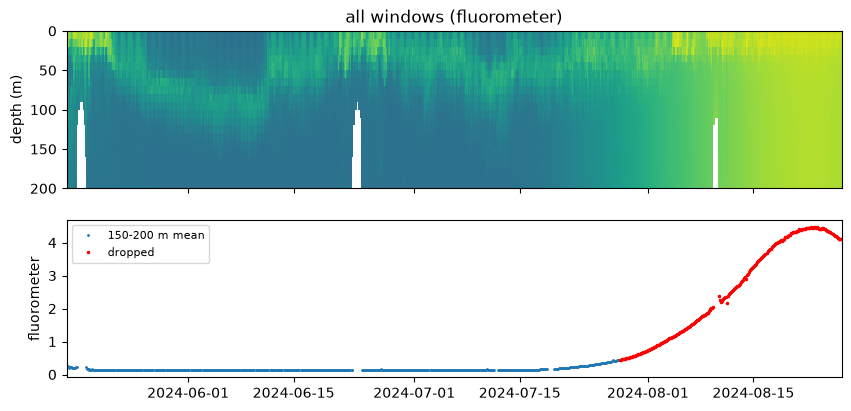

In [18]:
d_ = "sp025-20240515T2040"
w = pd.read_parquet(g.WIN_DIR / f"{d_}.parquet").sort_values("time")
bad = g.bad_window_mask(w, meta.max_z)
print(f"{d_}: {bad.sum()} of {len(w)} windows dropped; scan bad_days:", meta.loc[d_, "bad_days"])
fig, axs = plt.subplots(2, 1, figsize=(10, 4.5), sharex=True)
axs[0].pcolormesh(w.time, mid, np.log10(np.clip(w[b.CHLA_COLS].to_numpy(float), 0.01, None)).T,
                  vmin=-2, vmax=1, shading="nearest")
axs[0].set_ylim(200, 0); axs[0].set_ylabel("depth (m)"); axs[0].set_title("all windows (fluorometer)")
axs[1].plot(w.time, w[g.MID_COLS].mean(axis=1), ".", ms=2, label="150-200 m mean")
axs[1].plot(w.time[bad], w[g.MID_COLS].mean(axis=1)[bad], "r.", ms=3, label="dropped")
axs[1].set_ylabel("fluorometer"); axs[1].legend(fontsize=8);

In [19]:
import json, pyarrow.parquet as pq
counts = json.loads(pq.read_schema(b.DATA_DIR / "CHLA_glider_profiles.parquet").metadata[b"build_glider_counts"])
dropped = pd.Series({k: v["bad_windows_dropped"] for k, v in counts["by_dataset"].items()})
print(counts["bad_windows_dropped"], "windows dropped in", (dropped > 0).sum(), "deployments")
dropped[dropped > 0].sort_values(ascending=False).head(10).rename("dropped").to_frame()
print(counts["position_spikes_dropped"], "rows dropped as bad position fixes:",
      {k: v["position_spikes_dropped"] for k, v in counts["by_dataset"].items() if v["position_spikes_dropped"]})

1469 windows dropped in 41 deployments
6 rows dropped as bad position fixes: {'cp_379-20241120T1605-delayed': 2, 'sp030-20260701T1719': 1, 'sp058-20241121T1821': 1, 'sp062-20250702T1440': 1, 'sp213-20260916T1514': 1}


## 7. Check against the released table

In [20]:
# The month's windows (before the Sauzède division) against the table's raw columns.
m = win.merge(prof, on="profile_id", suffixes=("", "_table"))
m = m[m.time.dt.strftime("%Y-%m") == "2024-05"]
# Windows at the month's edges can differ: the table pools all months first.
diff = np.zeros(len(m), bool)
for c, f in zip(b.CHLA_COLS, fluor):
    diff |= ~np.isclose(m[c], m[f], equal_nan=True)
print(f"{len(m)} windows compared, {diff.sum()} differ")
assert diff.sum() <= 2

231 windows compared, 0 differ


## 8. The whole glider table

One deployment per region (the one with the most rows): the chosen profile
of each window, after QC and the Sauzède correction.

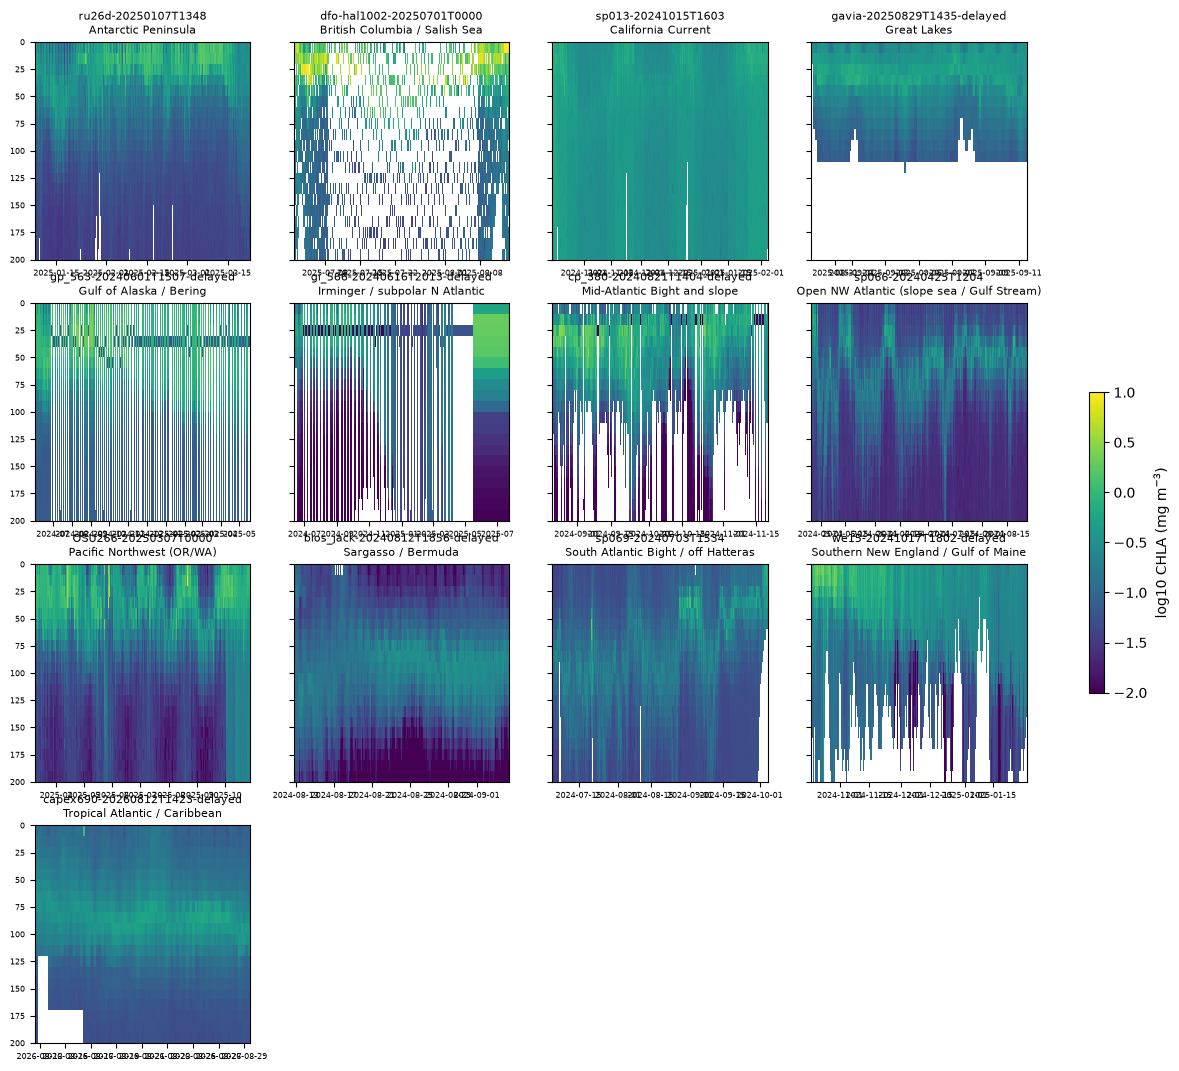

In [21]:
pick = prof.groupby(["region", "dataset_id"]).size().reset_index().sort_values(0).groupby("region").tail(1)
fig, axs = plt.subplots(4, 4, figsize=(16, 13), sharey=True)
for ax, (_, r_) in zip(axs.flat, pick.sort_values("region").iterrows()):
    w = prof[prof.dataset_id == r_.dataset_id].sort_values("time")
    im = ax.pcolormesh(w.time, mid, np.log10(np.clip(w[b.CHLA_COLS].to_numpy(float), 0.01, None)).T,
                       vmin=-2, vmax=1, shading="nearest")
    ax.set_title(f"{r_.dataset_id}\n{r_.region}", fontsize=8); ax.tick_params(labelsize=6)
for ax in axs.flat[len(pick):]:
    ax.set_visible(False)
axs[0, 0].set_ylim(200, 0)
fig.colorbar(im, ax=axs, shrink=0.3, label="log10 CHLA (mg m$^{-3}$)");

In [22]:
summary = prof.groupby("region").agg(
    deployments=("dataset_id", "nunique"), rows=("profile_id", "size"),
    median_shore_km=("shore_km", "median"), median_max_depth_m=("max_depth", "median"))
summary.round(1)

,deployments,rows,median_shore_km,median_max_depth_m
region,,,,
Antarctic Peninsula,2,955,32.1,199.4
British Columbia / Salish Sea,22,4245,111.1,178.8
California Current,54,32217,79.7,198.0
Great Lakes,1,104,21.5,107.4
Gulf of Alaska / Bering,17,8189,894.4,199.6
Irminger / subpolar N Atlantic,5,3465,198.4,199.8
Mid-Atlantic Bight and slope,93,22564,71.8,62.5
Open NW Atlantic (slope sea / Gulf Stream),5,1975,478.0,197.7
Pacific Northwest (OR/WA),42,15976,110.1,199.3


## 9. Matchups

The glider tables are matched exactly as Argo and OOI (methods notebooks 3
and 4): PACE V3.2 daily 4 km Rrs, chlor_a, Kd_490, a profile matching a
granule when its time is within 24 h after the granule's
`time_coverage_start` (standard before NRT, nearest cell); OLCI S3A/S3B daily
4 km Rrs from the file of the profile's UTC day. The choice of time rule is
discussed in fish-pace/fish-pace-datasets#10, which has a comparison of both
rules on these glider profiles.

In [23]:
rrs_cols = [f"pace_Rrs_{x}" for x in b.RRS_LABELS]
pace = pd.read_parquet(b.DATA_DIR / "CHLA_glider_profiles_plus_PACE.parquet")
olci = pd.read_parquet(b.DATA_DIR / "CHLA_glider_profiles_plus_OLCI.parquet")
v = pace[pace[rrs_cols].notna().any(axis=1)]
tab = prof.groupby("region").size().rename("profiles").to_frame()
tab["PACE granule"] = pace.groupby("region").size()
tab["PACE valid Rrs"] = v.groupby("region").size()
tab["OLCI valid Rrs_443"] = olci[np.isfinite(olci.olci_Rrs_443)].groupby("region").size()
tab["OLCI and PACE"] = olci[np.isfinite(olci.olci_Rrs_443) & olci.pace_Rrs_valid].groupby("region").size()
tab.loc["total"] = tab.sum()
tab.fillna(0).astype(int)

,profiles,PACE granule,PACE valid Rrs,OLCI valid Rrs_443,OLCI and PACE
region,,,,,
Antarctic Peninsula,955,914,88,72,28
British Columbia / Salish Sea,4245,4051,623,726,425
California Current,32217,30677,9418,9757,5859
Great Lakes,104,103,41,52,37
Gulf of Alaska / Bering,8189,7696,812,974,506
Irminger / subpolar N Atlantic,3465,3276,280,291,162
Mid-Atlantic Bight and slope,22564,21202,7489,7680,4638
Open NW Atlantic (slope sea / Gulf Stream),1975,1864,551,591,355
Pacific Northwest (OR/WA),15976,15244,3891,3907,2304


Matchups by local solar hour (the quenching question needs both day and night):

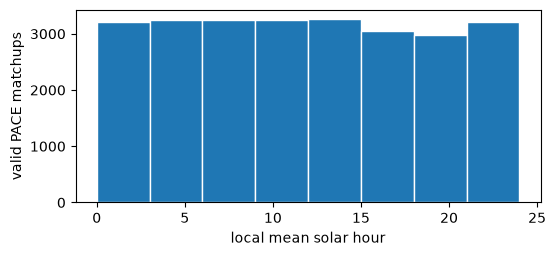

In [24]:
fig, ax = plt.subplots(figsize=(6, 2.5))
ax.hist(v.solar_hour, bins=np.arange(0, 25, 3), edgecolor="w")
ax.set_xlabel("local mean solar hour"); ax.set_ylabel("valid PACE matchups");

Distance to shore of the valid matchups. The table keeps `shore_km` (Natural
Earth 10 m coastline; Great Lakes shorelines for the Great Lakes deployment) so near-shore pixels can be filtered; PACE L3 already
masks land and many adjacency pixels.

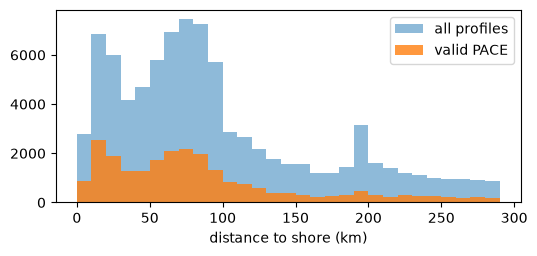

In [25]:
fig, ax = plt.subplots(figsize=(6, 2.5))
ax.hist(prof.shore_km, bins=np.arange(0, 300, 10), alpha=0.5, label="all profiles")
ax.hist(v.shore_km, bins=np.arange(0, 300, 10), alpha=0.8, label="valid PACE")
ax.set_xlabel("distance to shore (km)"); ax.legend();

Satellite chlorophyll against the glider's shallowest bin (Sauzède-corrected),
coloured by solar hour. This is only a sanity check, not a validation: the
glider bin is 0–10 m, the PACE value a daily 4 km composite.

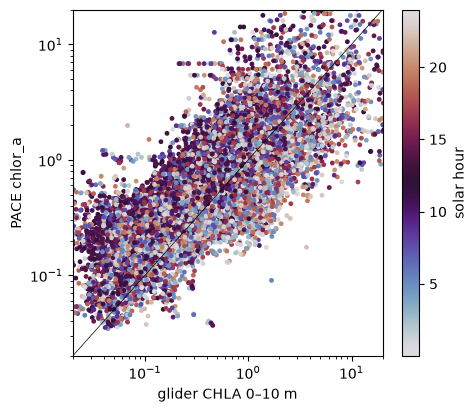

In [26]:
fig, ax = plt.subplots(figsize=(5, 4.5))
s = ax.scatter(v.CHLA_0_10, v.pace_chlor_a, c=v.solar_hour, cmap="twilight", s=6)
lim = [0.02, 20]
ax.plot(lim, lim, "k", lw=0.5); ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("glider CHLA 0–10 m"); ax.set_ylabel("PACE chlor_a")
fig.colorbar(s, label="solar hour");

The flat rows of very high PACE chlor_a (above 8 mg m⁻³, median about 13)
are near-shore atmospheric-correction failures: mostly within ~25 km of the
coast in the California Current and the Pacific Northwest, often with
Rrs(442) near zero or negative, and many times the glider value. They show
why `shore_km` is kept; a coastal training set needs a near-shore or
Rrs-quality filter (notebook 5, section 6, has the numbers by distance).

In [27]:
hi = v[v.pace_chlor_a > 8]
print(len(hi), "matchups with PACE chlor_a > 8; distance to shore (km):",
      hi.shore_km.round(1).describe()[["min", "50%", "max"]].to_dict())
hi[["dataset_id", "time", "shore_km", "CHLA_0_10", "pace_chlor_a", "pace_Rrs_442"]].head()

282 matchups with PACE chlor_a > 8; distance to shore (km): {'min': 0.7, '50%': 14.25, 'max': 61.4}


,dataset_id,time,shore_km,CHLA_0_10,pace_chlor_a,pace_Rrs_442
2491,sp028-20240403T1628,2024-04-11 00:52:26+00:00,17.348016,2.088644,13.989042,-0.00043
2505,sp028-20240403T1628,2024-04-11 03:55:46+00:00,19.147246,2.623310,13.989042,-0.00043
2513,sp028-20240403T1628,2024-04-11 06:58:38+00:00,20.347021,1.792359,13.989042,-0.00043
2525,sp028-20240403T1628,2024-04-11 10:03:07+00:00,21.716290,1.623093,21.845633,-0.00040
2540,sp028-20240403T1628,2024-04-11 13:02:24+00:00,22.794641,1.407075,21.845633,-0.00040


PACE chlor_a / glider CHLA_0_10 by local solar hour. Fluorescence quenching
in daylight lowers the glider value, so the ratio peaks around noon.

In [28]:
vv = v[(v.CHLA_0_10 > 0) & v.pace_chlor_a.notna()]
r = np.log10(vv.pace_chlor_a / vv.CHLA_0_10)
hb = pd.cut(vv.solar_hour, [0, 6, 9, 15, 18, 24], right=False)
(10 ** r.groupby(hb, observed=True).median()).round(2).rename("median PACE/glider").to_frame().assign(
    n=r.groupby(hb, observed=True).size())

,median PACE/glider,n
solar_hour,,
"[0, 6)",1.22,5960
"[6, 9)",1.48,2975
"[9, 15)",1.98,5976
"[15, 18)",1.45,2802
"[18, 24)",1.18,5657


The same ratio at night (solar hour outside 6–18 h, little quenching), with
and without subtracting `dark_offset`, for the gliders that have one. For
reference, Argo's night ratio in the released table is about 1.25.
The last line leaves out the deep-offset deployments (`deep_offset_flag`).

In [29]:
night = vv[~vv.solar_hour.between(6, 18) & vv.dark_offset.notna()]
dc = (night.CHLA_FLUOR_0_10 - night.dark_offset) / night.chla_ratio
ok = dc > 0
print(f"n = {len(night)}; night median PACE/glider, Sauzède only (CHLA_0_10): "
      f"{10 ** np.median(np.log10(night.pace_chlor_a / night.CHLA_0_10)):.2f}")
print(f"with dark_offset subtracted: "
      f"{10 ** np.median(np.log10(night.pace_chlor_a[ok] / dc[ok])):.2f} (n = {ok.sum()})")
n2 = vv[~vv.solar_hour.between(6, 18) & ~vv.deep_offset_flag]
print(f"all night rows without deep_offset_flag (n = {len(n2)}): "
      f"{10 ** np.median(np.log10(n2.pace_chlor_a / n2.CHLA_0_10)):.2f}")

n = 7508; night median PACE/glider, Sauzède only (CHLA_0_10): 1.09
with dark_offset subtracted: 1.92 (n = 7275)
all night rows without deep_offset_flag (n = 9650): 1.27
